In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# Устанавливаем Times New Roman как семейство шрифтов (serif)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']

# Устанавливаем 12 размер для всех элементов (заголовки, подписи осей, тики)
plt.rcParams['font.size'] = 12

# Дополнительно: чтобы цифры на осях тоже отображались в Times New Roman
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

In [3]:
df = pd.read_excel('data_startups.xlsx', sheet_name='data')
df

,link,state_success,pledged_amount,backers_count,funding_ratio,goal_amount,currency,launched_at,deadline,duration_days,...,story_word_count,story_image_count,story_external_links_count,has_faq_section,risks_word_count,ai_keyword_count,creator_created_projects,creator_competence_count,year,gii
0,https://www.kickstarter.com/projects/stefano-d...,0,51.0,2,0.000010,5000000,EUR,2023-11-08T01:16:08+00:00,2024-01-07T01:16:08+00:00,60,...,518,0,0,0,248,3,0,2,2024,45.325561
1,https://www.kickstarter.com/projects/rikicoder...,0,113.0,4,0.022600,5000,EUR,2024-06-23T00:20:50+00:00,2024-08-22T00:20:50+00:00,60,...,567,1,0,0,47,0,0,0,2024,45.325561
2,https://www.kickstarter.com/projects/201544559...,0,255.0,21,0.020400,12500,EUR,2025-04-13T16:05:56+00:00,2025-05-28T16:05:56+00:00,45,...,248,0,0,1,81,0,0,0,2025,44.944740
3,https://www.kickstarter.com/projects/ortonai/o...,0,11.0,2,0.001864,5900,EUR,2025-01-30T03:08:20+00:00,2025-03-01T03:08:20+00:00,30,...,887,9,2,0,99,0,0,0,2025,44.944740
4,https://www.kickstarter.com/projects/banta-ai/...,0,980.0,5,0.016333,60000,EUR,2025-04-15T16:10:41+00:00,2025-05-15T16:10:41+00:00,30,...,818,5,0,1,226,2,0,0,2025,44.944740
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,https://www.kickstarter.com/projects/deglace/f...,1,439664.0,796,29.310933,15000,USD,2025-09-30T14:01:16+00:00,2025-11-14T15:01:16+00:00,45,...,356,0,8,1,8,0,0,0,2025,61.689211
996,https://www.kickstarter.com/projects/gymera/hy...,1,1817837.0,155,181.783700,10000,HKD,2025-06-05T14:00:05+00:00,2025-08-04T14:00:05+00:00,60,...,356,0,8,1,8,0,1,1,2025,51.463955
997,https://www.kickstarter.com/projects/eduonix/c...,1,3718.0,34,7.436000,500,USD,2025-12-10T12:01:09+00:00,2025-12-18T12:30:00+00:00,8,...,356,0,8,0,8,0,1,0,2025,61.689211
998,https://www.kickstarter.com/projects/fatihtokl...,1,1619.0,19,1.619000,1000,EUR,2023-08-22T12:03:59+00:00,2023-10-21T12:03:59+00:00,60,...,356,0,8,1,8,0,0,0,2023,58.755365


In [4]:
df.isna().sum()

link                            0
state_success                   0
pledged_amount                  0
backers_count                   0
funding_ratio                   0
goal_amount                     0
currency                        0
launched_at                     0
deadline                        0
duration_days                   0
category_main                   0
category_sub                   94
created_location_country        0
title_length_chars              0
has_video                       0
story_word_count                0
story_image_count               0
story_external_links_count      0
has_faq_section                 0
risks_word_count                0
ai_keyword_count                0
creator_created_projects        0
creator_competence_count        0
year                            0
gii                           180
dtype: int64

In [5]:
df.duplicated().sum()

0

In [6]:
work = df.copy().dropna()
work

,link,state_success,pledged_amount,backers_count,funding_ratio,goal_amount,currency,launched_at,deadline,duration_days,...,story_word_count,story_image_count,story_external_links_count,has_faq_section,risks_word_count,ai_keyword_count,creator_created_projects,creator_competence_count,year,gii
0,https://www.kickstarter.com/projects/stefano-d...,0,51.0,2,0.000010,5000000,EUR,2023-11-08T01:16:08+00:00,2024-01-07T01:16:08+00:00,60,...,518,0,0,0,248,3,0,2,2024,45.325561
1,https://www.kickstarter.com/projects/rikicoder...,0,113.0,4,0.022600,5000,EUR,2024-06-23T00:20:50+00:00,2024-08-22T00:20:50+00:00,60,...,567,1,0,0,47,0,0,0,2024,45.325561
2,https://www.kickstarter.com/projects/201544559...,0,255.0,21,0.020400,12500,EUR,2025-04-13T16:05:56+00:00,2025-05-28T16:05:56+00:00,45,...,248,0,0,1,81,0,0,0,2025,44.944740
3,https://www.kickstarter.com/projects/ortonai/o...,0,11.0,2,0.001864,5900,EUR,2025-01-30T03:08:20+00:00,2025-03-01T03:08:20+00:00,30,...,887,9,2,0,99,0,0,0,2025,44.944740
4,https://www.kickstarter.com/projects/banta-ai/...,0,980.0,5,0.016333,60000,EUR,2025-04-15T16:10:41+00:00,2025-05-15T16:10:41+00:00,30,...,818,5,0,1,226,2,0,0,2025,44.944740
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,https://www.kickstarter.com/projects/deglace/f...,1,439664.0,796,29.310933,15000,USD,2025-09-30T14:01:16+00:00,2025-11-14T15:01:16+00:00,45,...,356,0,8,1,8,0,0,0,2025,61.689211
996,https://www.kickstarter.com/projects/gymera/hy...,1,1817837.0,155,181.783700,10000,HKD,2025-06-05T14:00:05+00:00,2025-08-04T14:00:05+00:00,60,...,356,0,8,1,8,0,1,1,2025,51.463955
997,https://www.kickstarter.com/projects/eduonix/c...,1,3718.0,34,7.436000,500,USD,2025-12-10T12:01:09+00:00,2025-12-18T12:30:00+00:00,8,...,356,0,8,0,8,0,1,0,2025,61.689211
998,https://www.kickstarter.com/projects/fatihtokl...,1,1619.0,19,1.619000,1000,EUR,2023-08-22T12:03:59+00:00,2023-10-21T12:03:59+00:00,60,...,356,0,8,1,8,0,0,0,2023,58.755365


In [7]:
pd.set_option('display.float_format', '{:.2f}'.format)
n = work.describe().transpose()
n
#n.to_csv('descr_num.csv')


,count,mean,std,min,25%,50%,75%,max
state_success,756.00,0.46,0.50,0.00,0.00,0.00,1.00,1.00
pledged_amount,756.00,531931.98,3018961.62,0.00,82.33,2109.59,77608.75,54970803.46
backers_count,756.00,423.28,1620.15,0.00,3.00,11.00,165.00,18682.00
funding_ratio,756.00,16.17,52.98,0.00,0.01,0.24,8.95,700.31
goal_amount,756.00,179890.31,2125894.47,1.00,5000.00,15000.00,50000.00,53655600.00
duration_days,756.00,37.00,13.35,1.00,30.00,30.00,45.00,60.00
title_length_chars,756.00,45.76,14.05,3.00,39.00,50.00,57.00,60.00
has_video,756.00,0.80,0.40,0.00,1.00,1.00,1.00,1.00
story_word_count,756.00,447.33,343.82,60.00,356.00,356.00,356.00,3841.00
story_image_count,756.00,4.68,17.60,0.00,0.00,0.00,0.00,135.00


In [8]:
k = work[['currency', 'category_main', 'category_sub', 'created_location_country']].describe().transpose()
k
#k.to_csv('descr_cat.csv')

,count,unique,top,freq
currency,756,15,USD,353
category_main,756,1,Technology,756
category_sub,756,15,Apps,190
created_location_country,756,38,United States,358


Описательная статистика показывает асимметрию распределения в сторону положительных значений, особенно для переменных, связанных с финансированием, где небольшое количество очень успешных кампаний смещает среднее значение в сторону увеличения. Средний коэффициент финансирования составляет 16,17, но медиана — всего 0,24, а максимальное значение достигает 700,31.  В большинстве кампаний используется ограниченное количество терминов, связанных с искусственным интеллектом, и их запускают относительно неопытные основатели.  Только 26 % основателей ранее запускали проекты.  Свойства распределения оправдывают использование логарифмических преобразований.

**Одномерный анализ числовых признаков**

In [9]:
work.info()

<class 'pandas.core.frame.DataFrame'>
Index: 756 entries, 0 to 999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   link                        756 non-null    object 
 1   state_success               756 non-null    int64  
 2   pledged_amount              756 non-null    float64
 3   backers_count               756 non-null    int64  
 4   funding_ratio               756 non-null    float64
 5   goal_amount                 756 non-null    int64  
 6   currency                    756 non-null    object 
 7   launched_at                 756 non-null    object 
 8   deadline                    756 non-null    object 
 9   duration_days               756 non-null    int64  
 10  category_main               756 non-null    object 
 11  category_sub                756 non-null    object 
 12  created_location_country    756 non-null    object 
 13  title_length_chars          756 non-null

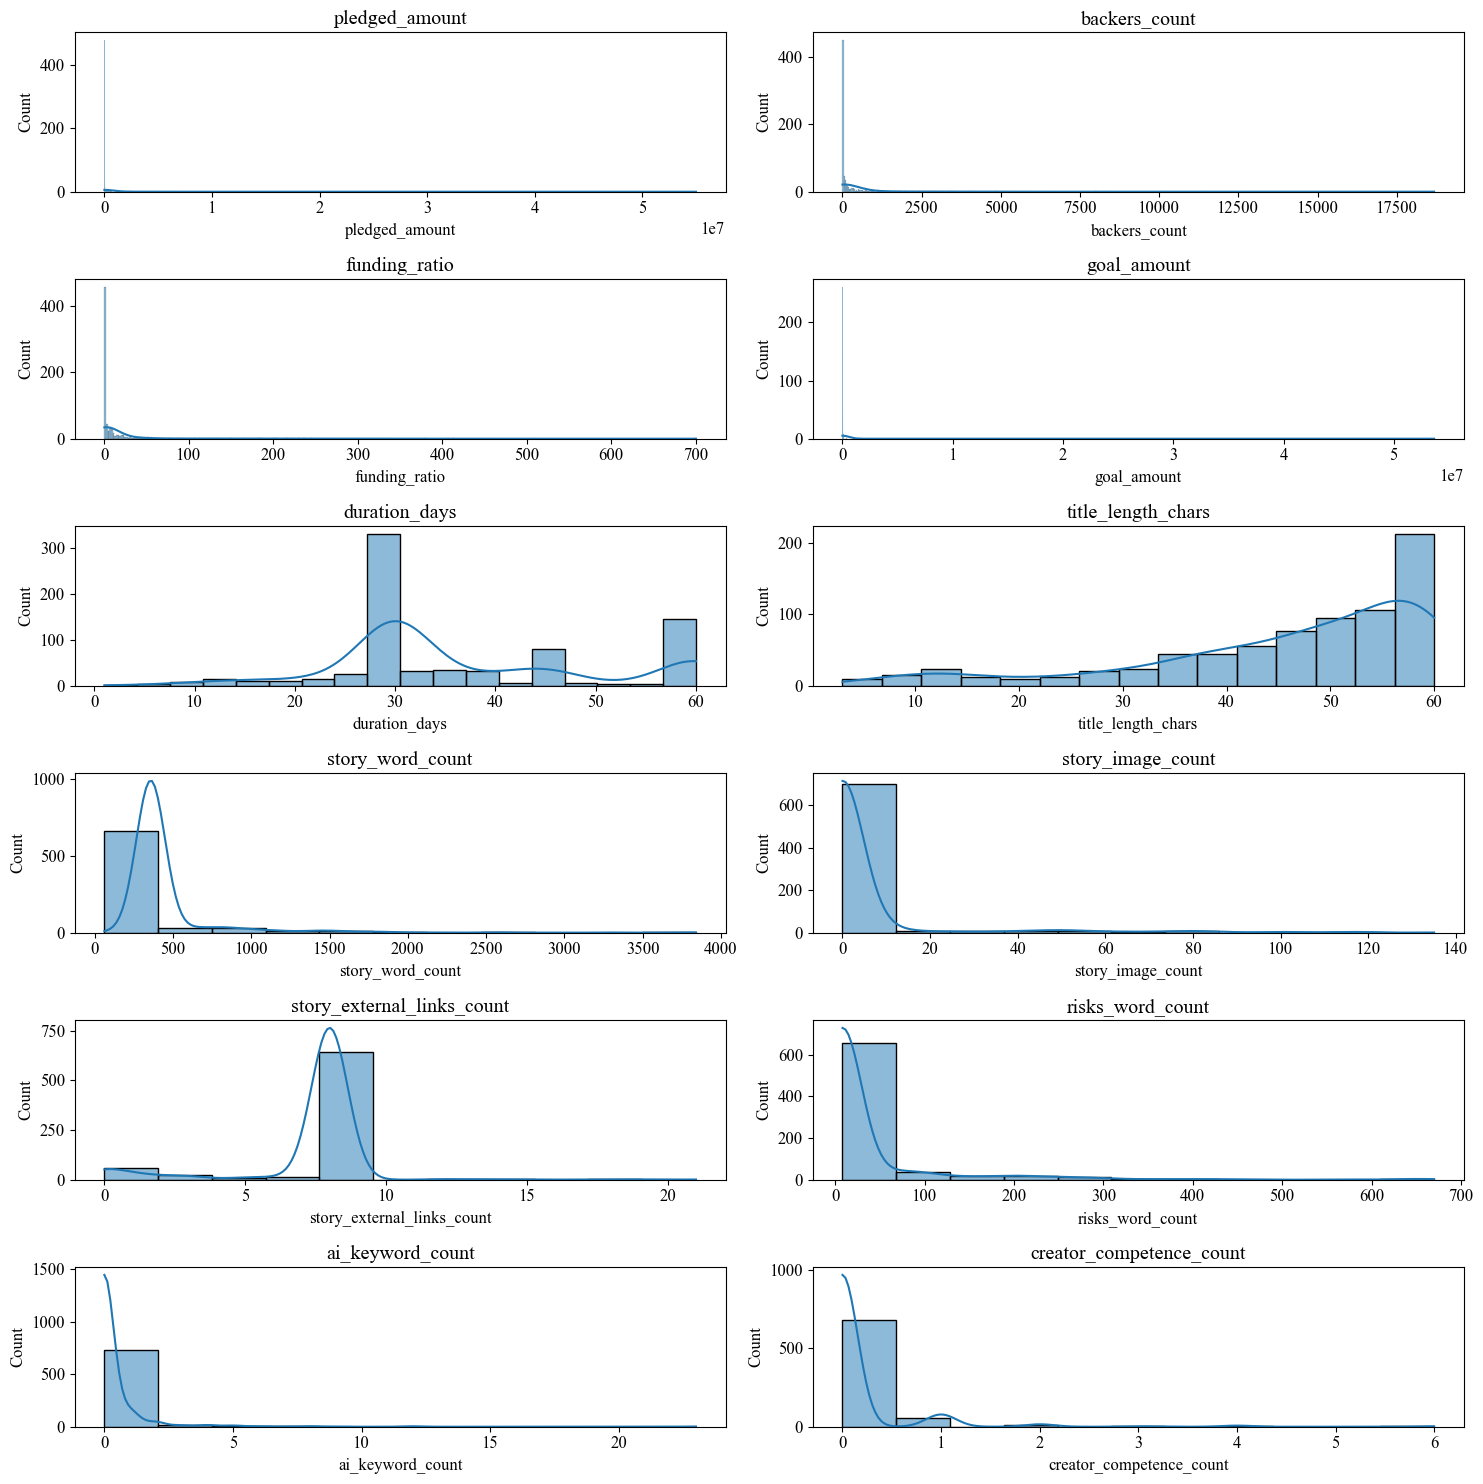

In [10]:
num_cols = ['pledged_amount', 'backers_count', 'funding_ratio', 'goal_amount', 
            'duration_days', 'title_length_chars', 'story_word_count', 
            'story_image_count', 'story_external_links_count', 'risks_word_count',
            'ai_keyword_count', 'creator_competence_count']

fig, axes = plt.subplots(nrows=6, ncols=2, figsize=(15, 15))

axes = axes.flatten() 

for i, col in enumerate(num_cols):
    sns.histplot(work[col], kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

<Axes: xlabel='gii', ylabel='Count'>

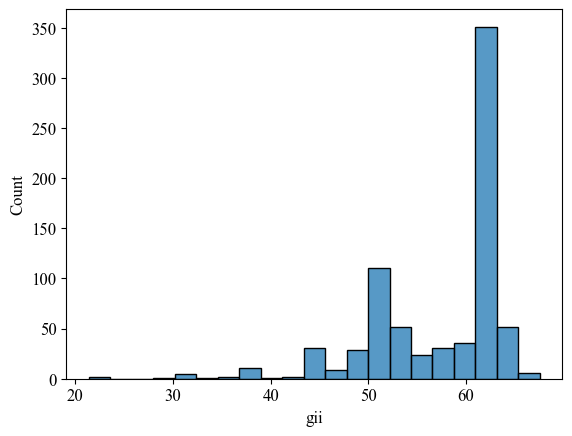

In [11]:
sns.histplot(work['gii'])

Из-за сильной асимметрии было применено логарифмическое преобразование. Для сохранения нулевых значений используется функция Log(x+1).

In [12]:
work['log_pledged_amount'] = np.log(df['pledged_amount'] + 1)
work['log_backers_count'] = np.log(df['backers_count'] + 1)
work['log_goal_amount'] = np.log(df['goal_amount'] + 1)
work['log_funding_ratio'] = np.log(df['funding_ratio'] + 1)
work['log_story_word_count'] = np.log(df['story_word_count'] + 1)
work['log_story_image_count'] = np.log(df['story_image_count'] + 1)
work['log_risks_word_count'] = np.log(df['risks_word_count'] + 1)
work['log_ai_keyword_count'] = np.log(df['ai_keyword_count'] + 1)

Text(0.5, 0, 'Funding ratio')

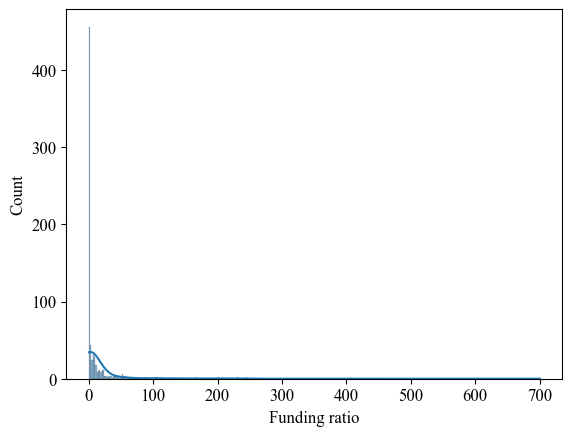

In [13]:
sns.histplot(work['funding_ratio'], kde=True)
plt.xlabel("Funding ratio")

Text(0.5, 0, 'Log (Funding ratio)')

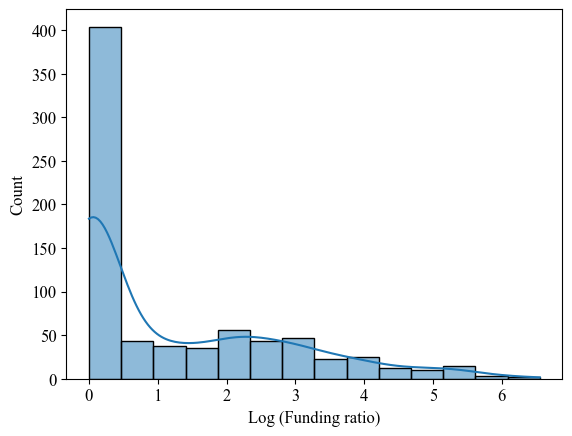

In [14]:
sns.histplot(work['log_funding_ratio'], kde=True)
plt.xlabel("Log (Funding ratio)")

In [15]:
work['gii'].max()

67.5888136106804

In [16]:
work['gii'].min()

21.3791141049195

In [17]:
work.to_csv('final_data.csv')

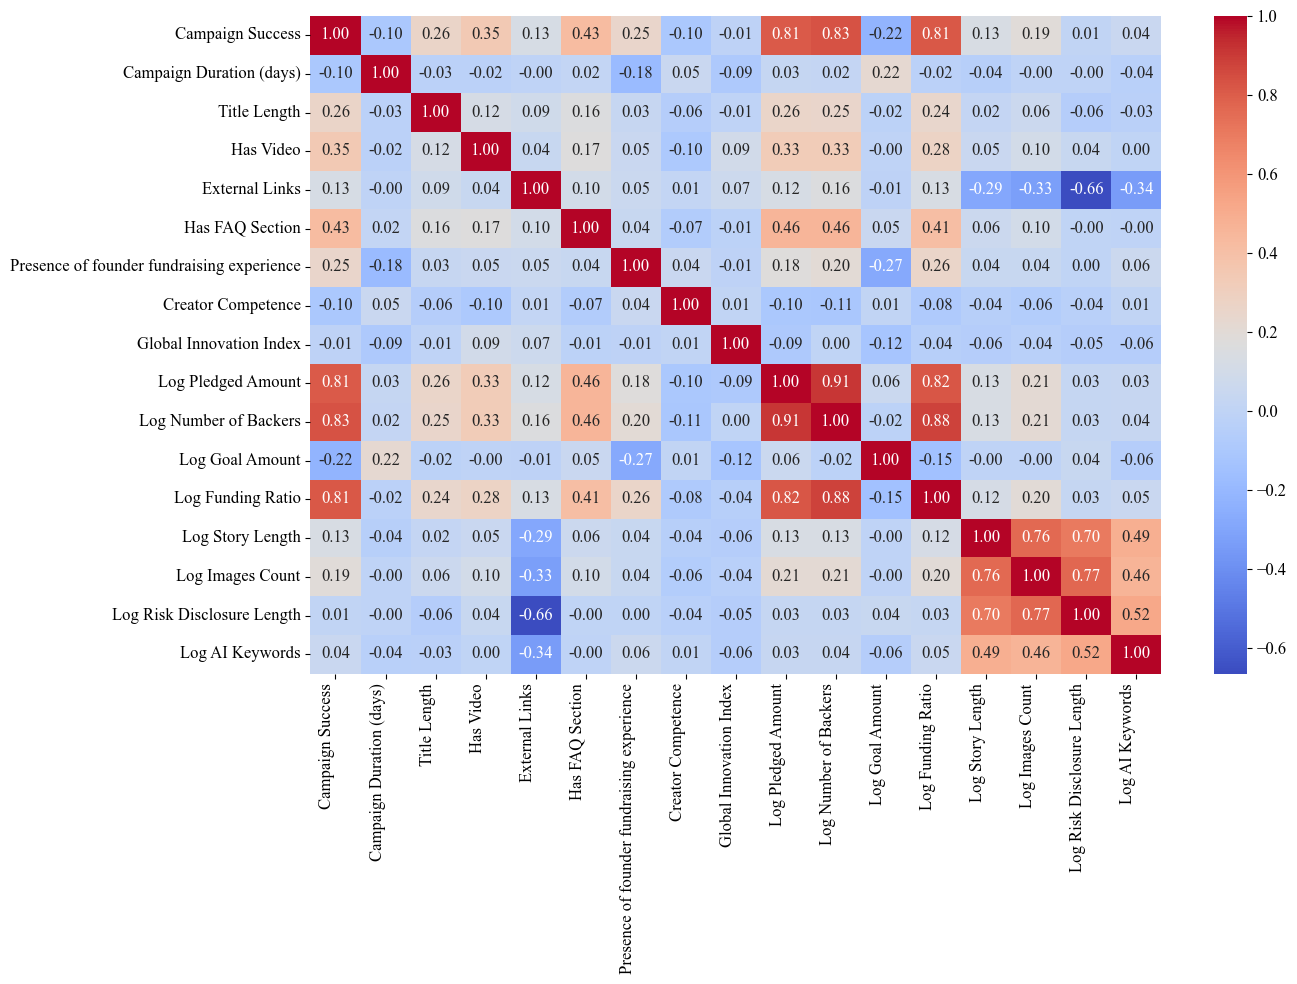

In [17]:

# словарь с человекочитаемыми названиями
rename_dict = {
    'state_success': 'Campaign Success',
    'duration_days': 'Campaign Duration (days)',
    'title_length_chars': 'Title Length',
    'has_video': 'Has Video',
    'story_external_links_count': 'External Links',
    'has_faq_section': 'Has FAQ Section',
    'creator_created_projects': 'Presence of founder fundraising experience',
    'creator_competence_count': 'Creator Competence',
    'gii': 'Global Innovation Index',
    'log_pledged_amount': 'Log Pledged Amount',
    'log_backers_count': 'Log Number of Backers',
    'log_goal_amount': 'Log Goal Amount',
    'log_funding_ratio': 'Log Funding Ratio',
    'log_story_word_count': 'Log Story Length',
    'log_story_image_count': 'Log Images Count',
    'log_risks_word_count': 'Log Risk Disclosure Length',
    'log_ai_keyword_count': 'Log AI Keywords'
}

corr = (
    work.select_dtypes(include='number')
    .drop(columns=[
        'pledged_amount', 'backers_count', 'goal_amount',
        'funding_ratio', 'story_word_count', 'story_image_count',
        'risks_word_count', 'ai_keyword_count', 'year'
    ])
    .rename(columns=rename_dict)
    .corr()
)

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.xticks(rotation=90, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

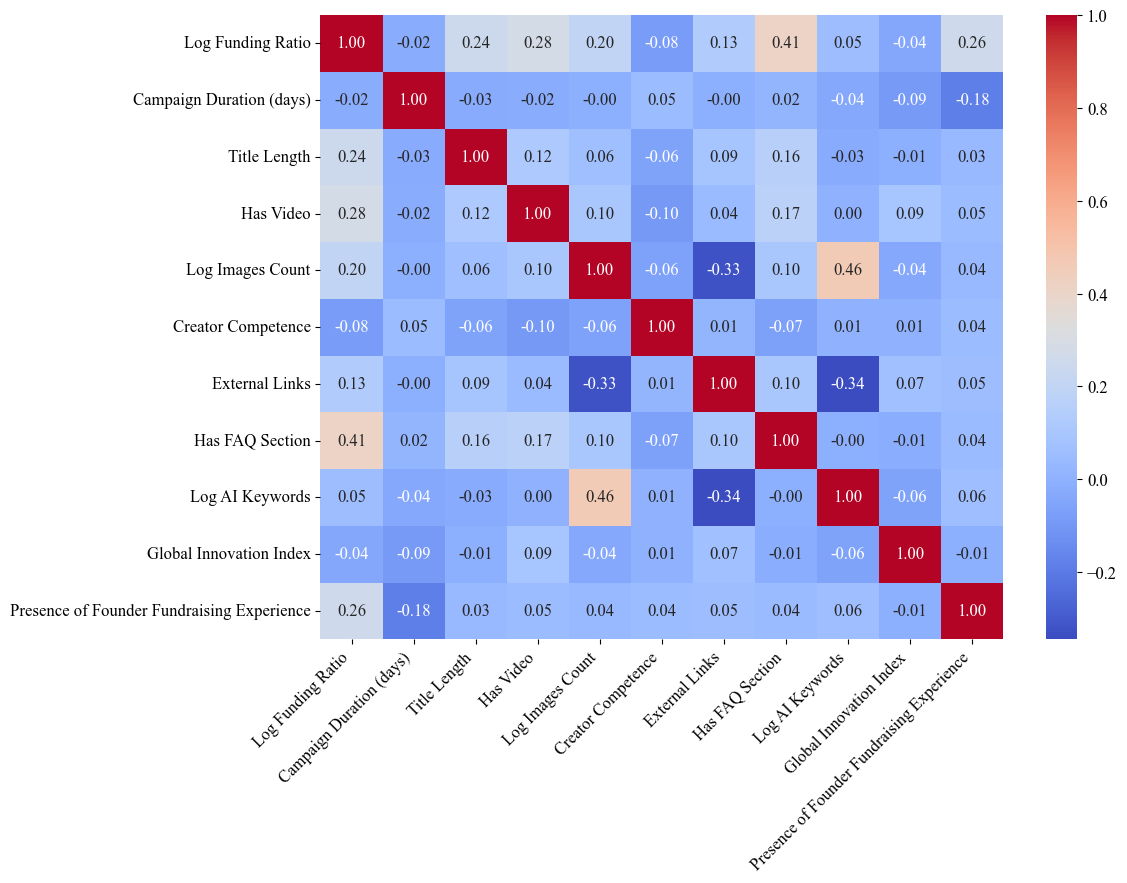

In [18]:
# словарь с человекочитаемыми названиями
rename_dict = {
    'log_funding_ratio': 'Log Funding Ratio',
    'duration_days': 'Campaign Duration (days)',
    'title_length_chars': 'Title Length',
    'has_video': 'Has Video',
    'log_story_image_count': 'Log Images Count',
    'creator_competence_count': 'Creator Competence',
    'story_external_links_count': 'External Links',
    'has_faq_section': 'Has FAQ Section',
    'log_ai_keyword_count': 'Log AI Keywords',
    'gii': 'Global Innovation Index',
    'creator_created_projects': 'Presence of Founder Fundraising Experience'
}

# оставляем только нужные переменные
corr = (
    work[
        [
            'log_funding_ratio',
            'duration_days',
            'title_length_chars',
            'has_video',
            'log_story_image_count',
            'creator_competence_count',
            'story_external_links_count',
            'has_faq_section',
            'log_ai_keyword_count',
            'gii',
            'creator_created_projects'
        ]
    ]
    .rename(columns=rename_dict)
    .corr()
)

# heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
corr_vars = [
    'log_funding_ratio',
    'story_external_links_count',
    'has_faq_section',
    'log_ai_keyword_count',
    'creator_created_projects',
    'gii',
    'duration_days',
    'title_length_chars',
    'has_video',
    'log_story_image_count',
    'creator_competence_count'
]


corr_names = {
    'log_funding_ratio': 'Crowdfunding success (log)',
    'story_external_links_count': 'Number of external links (count)',
    'has_faq_section': 'FAQ section presence (dummy)',
    'log_ai_keyword_count': 'AI-related signaling (log)',
    'creator_created_projects': 'Founder fundraising experience (dummy)',
    'gii': 'Home-country technological legitimacy (GII)',
    'duration_days': 'Campaign duration (count)',
    'title_length_chars': 'Title length (count)',
    'has_video': 'Video presence (dummy)',
    'log_story_image_count': 'Image count (log)',
    'creator_competence_count': "Creator’s competences (count)"
}

corr_table = (
    work[corr_vars]
    .rename(columns=corr_names)
    .corr(method='pearson')
    .round(2)
)

corr_table.to_csv('corr_table_article.csv')

Чтобы изучить взаимосвязи между основными переменными и обеспечить стабильность модели, мы оценили мультиколлинеарность с помощью корреляционной тепловой карты. На основании полученных данных такие переменные, как логарифм числа спонсоров, логарифм количества слов в описании и количество слов о рисках, были исключены из окончательной спецификации из-за высокой корреляции с другими предикторами.

Была выявлена сильная положительная корреляция между успешностью кампании и ключевыми показателями сбора средств, включая сумму пожертвований (корреляция = 0,81), количество спонсоров (корреляция = 0,83) и долю финансирования (корреляция = 0,81), что отражает концептуальное сходство этих показателей.  Такие характеристики кампании, как наличие раздела с часто задаваемыми вопросами (корреляция = 0,43) и видеоконтента (корреляция = 0,35), умеренно положительно коррелируют с успешностью кампании, что указывает на их потенциальную роль в качестве показателей надёжности.  Существенной корреляции между Глобальным инновационным индексом и успешностью кампании выявлено не было, что указывает на то, что факторы макроуровня могут не оказывать прямого влияния на результаты, а действовать через эффект взаимодействия.  Сильная корреляция между переменными, связанными с контентом, позволяет предположить, что в более подробных кампаниях, как правило, больше изображений, более длинные описания и более подробные сведения о рисках.  Внешние ссылки отрицательно коррелируют с несколькими переменными, связанными с контентом, в частности с раскрытием информации о рисках (корреляция = -0,66), что указывает на использование альтернативных коммуникационных стратегий в разных кампаниях.

In [19]:
work['deadline'].max()

'2026-03-15T14:59:42+00:00'

In [20]:
work['deadline'].min()

'2021-01-15T18:00:00+00:00'

In [21]:
df.columns

Index(['link', 'state_success', 'pledged_amount', 'backers_count',
       'funding_ratio', 'goal_amount', 'currency', 'launched_at', 'deadline',
       'duration_days', 'category_main', 'category_sub',
       'created_location_country', 'title_length_chars', 'has_video',
       'story_word_count', 'story_image_count', 'story_external_links_count',
       'has_faq_section', 'risks_word_count', 'ai_keyword_count',
       'creator_created_projects', 'creator_competence_count', 'year', 'gii'],
      dtype='object')

In [22]:
top_10 = work['created_location_country'].value_counts().head(15)
work['countries'] = work['created_location_country'].apply(lambda x: x if x in top_10 else 'Other')

<Axes: xlabel='count', ylabel='countries'>

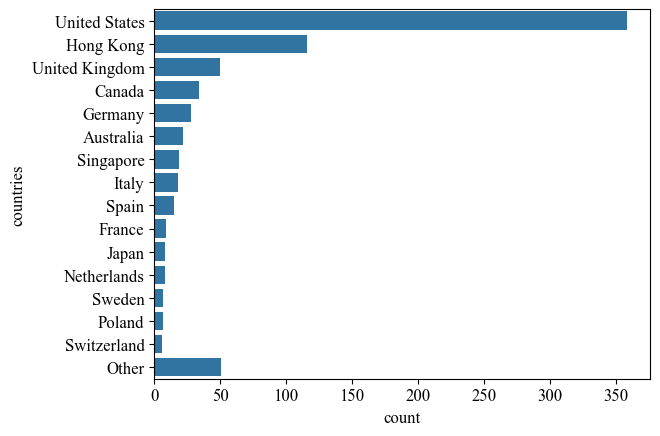

In [23]:
sns.countplot(
    y=work['countries'],
    order=[x for x in work['countries'].value_counts().index if x != 'Other'] + ['Other']
)

In [27]:
round ( work[work['countries'] == 'United States'].count() / work['link'].count(), 2)*100

link                         47.00
state_success                47.00
pledged_amount               47.00
backers_count                47.00
funding_ratio                47.00
goal_amount                  47.00
currency                     47.00
launched_at                  47.00
deadline                     47.00
duration_days                47.00
category_main                47.00
category_sub                 47.00
created_location_country     47.00
title_length_chars           47.00
has_video                    47.00
story_word_count             47.00
story_image_count            47.00
story_external_links_count   47.00
has_faq_section              47.00
risks_word_count             47.00
ai_keyword_count             47.00
creator_created_projects     47.00
creator_competence_count     47.00
year                         47.00
gii                          47.00
log_pledged_amount           47.00
log_backers_count            47.00
log_goal_amount              47.00
log_funding_ratio   

In [28]:
round ( work[work['countries'] == 'Hong Kong'].count() / work['countries'].count(), 2)*100

link                         15.00
state_success                15.00
pledged_amount               15.00
backers_count                15.00
funding_ratio                15.00
goal_amount                  15.00
currency                     15.00
launched_at                  15.00
deadline                     15.00
duration_days                15.00
category_main                15.00
category_sub                 15.00
created_location_country     15.00
title_length_chars           15.00
has_video                    15.00
story_word_count             15.00
story_image_count            15.00
story_external_links_count   15.00
has_faq_section              15.00
risks_word_count             15.00
ai_keyword_count             15.00
creator_created_projects     15.00
creator_competence_count     15.00
year                         15.00
gii                          15.00
log_pledged_amount           15.00
log_backers_count            15.00
log_goal_amount              15.00
log_funding_ratio   

In [29]:
round ( work[work['countries'] == 'United Kingdom'].count() / work['link'].count(), 2)*100

link                         7.00
state_success                7.00
pledged_amount               7.00
backers_count                7.00
funding_ratio                7.00
goal_amount                  7.00
currency                     7.00
launched_at                  7.00
deadline                     7.00
duration_days                7.00
category_main                7.00
category_sub                 7.00
created_location_country     7.00
title_length_chars           7.00
has_video                    7.00
story_word_count             7.00
story_image_count            7.00
story_external_links_count   7.00
has_faq_section              7.00
risks_word_count             7.00
ai_keyword_count             7.00
creator_created_projects     7.00
creator_competence_count     7.00
year                         7.00
gii                          7.00
log_pledged_amount           7.00
log_backers_count            7.00
log_goal_amount              7.00
log_funding_ratio            7.00
log_story_word

Набор данных охватывает международный рынок и включает кампании из 38 стран. Географическое распределение сильно смещено.  На долю США приходится около 47 % всех наблюдений.  Вторая по величине географическая группа — Гонконг (около 15 %), за ним следует Великобритания (около 7 %).  Остальные страны представлены в выборке в меньшем объеме.

In [31]:
round ( work[work['category_sub'] == 'Apps'].count() / work['link'].count(), 2)*100

link                         25.00
state_success                25.00
pledged_amount               25.00
backers_count                25.00
funding_ratio                25.00
goal_amount                  25.00
currency                     25.00
launched_at                  25.00
deadline                     25.00
duration_days                25.00
category_main                25.00
category_sub                 25.00
created_location_country     25.00
title_length_chars           25.00
has_video                    25.00
story_word_count             25.00
story_image_count            25.00
story_external_links_count   25.00
has_faq_section              25.00
risks_word_count             25.00
ai_keyword_count             25.00
creator_created_projects     25.00
creator_competence_count     25.00
year                         25.00
gii                          25.00
log_pledged_amount           25.00
log_backers_count            25.00
log_goal_amount              25.00
log_funding_ratio   

In [32]:
round ( work[work['category_sub'] == 'Software'].count() / work['link'].count(), 2)*100

link                         22.00
state_success                22.00
pledged_amount               22.00
backers_count                22.00
funding_ratio                22.00
goal_amount                  22.00
currency                     22.00
launched_at                  22.00
deadline                     22.00
duration_days                22.00
category_main                22.00
category_sub                 22.00
created_location_country     22.00
title_length_chars           22.00
has_video                    22.00
story_word_count             22.00
story_image_count            22.00
story_external_links_count   22.00
has_faq_section              22.00
risks_word_count             22.00
ai_keyword_count             22.00
creator_created_projects     22.00
creator_competence_count     22.00
year                         22.00
gii                          22.00
log_pledged_amount           22.00
log_backers_count            22.00
log_goal_amount              22.00
log_funding_ratio   

In [33]:
round ( work[work['category_sub'] == 'Hardware'].count() / work['link'].count(), 2)*100

link                         13.00
state_success                13.00
pledged_amount               13.00
backers_count                13.00
funding_ratio                13.00
goal_amount                  13.00
currency                     13.00
launched_at                  13.00
deadline                     13.00
duration_days                13.00
category_main                13.00
category_sub                 13.00
created_location_country     13.00
title_length_chars           13.00
has_video                    13.00
story_word_count             13.00
story_image_count            13.00
story_external_links_count   13.00
has_faq_section              13.00
risks_word_count             13.00
ai_keyword_count             13.00
creator_created_projects     13.00
creator_competence_count     13.00
year                         13.00
gii                          13.00
log_pledged_amount           13.00
log_backers_count            13.00
log_goal_amount              13.00
log_funding_ratio   

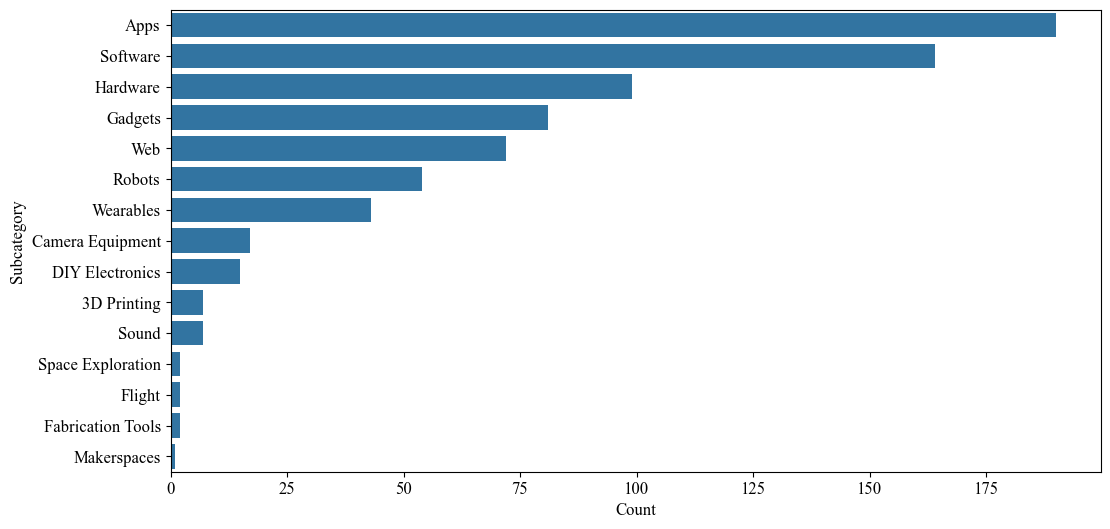

In [25]:
# человекочитаемые названия категорий
category_labels = {
    'apps': 'Apps',
    'camera equipment': 'Camera Equipment',
    'diy electronics': 'DIY Electronics',
    'fabrication tools': 'Fabrication Tools',
    'flight': 'Flight',
    'gadgets': 'Gadgets',
    'hardware': 'Hardware',
    'makerspaces': 'Makerspaces',
    'robots': 'Robots',
    'software': 'Software',
    'sound': 'Sound',
    'space exploration': 'Space Exploration',
    'wearables': 'Wearables',
    'web': 'Web',
    '3d printing': '3D Printing'
}

# создаем колонку с красивыми названиями
work['category_sub_readable'] = (
    work['category_sub']
    .str.lower()
    .map(category_labels)
)

# порядок по убыванию количества
order = (
    work['category_sub_readable']
    .value_counts()
    .index
)

# график
plt.figure(figsize=(12, 6))

sns.countplot(
    y=work['category_sub_readable'],
    order=order
)

plt.xlabel('Count')
plt.ylabel('Subcategory')

plt.show()

Что касается технологических подкатегорий, то на приложения приходится около 25% собранных данных о краудфандинговых кампаниях, за ними следуют проекты в области программного (около 22%) и аппаратного (около 13%) обеспечения.  Это свидетельствует о том, что краудфандинговая деятельность, связанная с искусственным интеллектом, в нашем наборе данных сосредоточена в основном в областях, связанных с программным обеспечением.

In [28]:
work['launched_at'] = pd.to_datetime(work['launched_at'])
work.info()

<class 'pandas.core.frame.DataFrame'>
Index: 756 entries, 0 to 999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype              
---  ------                      --------------  -----              
 0   link                        756 non-null    object             
 1   state_success               756 non-null    int64              
 2   pledged_amount              756 non-null    float64            
 3   backers_count               756 non-null    int64              
 4   funding_ratio               756 non-null    float64            
 5   goal_amount                 756 non-null    int64              
 6   currency                    756 non-null    object             
 7   launched_at                 756 non-null    datetime64[ns, UTC]
 8   deadline                    756 non-null    object             
 9   duration_days               756 non-null    int64              
 10  category_main               756 non-null    object             
 11

In [29]:
work.head()

,link,state_success,pledged_amount,backers_count,funding_ratio,goal_amount,currency,launched_at,deadline,duration_days,...,log_pledged_amount,log_backers_count,log_goal_amount,log_funding_ratio,log_story_word_count,log_story_image_count,log_risks_word_count,log_ai_keyword_count,countries,category_sub_readable
0,https://www.kickstarter.com/projects/stefano-d...,0,51.00,2,0.00,5000000,EUR,2023-11-08 01:16:08+00:00,2024-01-07T01:16:08+00:00,60,...,3.95,1.10,15.42,0.00,6.25,0.00,5.52,1.39,Italy,Software
1,https://www.kickstarter.com/projects/rikicoder...,0,113.00,4,0.02,5000,EUR,2024-06-23 00:20:50+00:00,2024-08-22T00:20:50+00:00,60,...,4.74,1.61,8.52,0.02,6.34,0.69,3.87,0.00,Italy,Apps
2,https://www.kickstarter.com/projects/201544559...,0,255.00,21,0.02,12500,EUR,2025-04-13 16:05:56+00:00,2025-05-28T16:05:56+00:00,45,...,5.55,3.09,9.43,0.02,5.52,0.00,4.41,0.00,Italy,Software
3,https://www.kickstarter.com/projects/ortonai/o...,0,11.00,2,0.00,5900,EUR,2025-01-30 03:08:20+00:00,2025-03-01T03:08:20+00:00,30,...,2.48,1.10,8.68,0.00,6.79,2.30,4.61,0.00,Italy,Web
4,https://www.kickstarter.com/projects/banta-ai/...,0,980.00,5,0.02,60000,EUR,2025-04-15 16:10:41+00:00,2025-05-15T16:10:41+00:00,30,...,6.89,1.79,11.00,0.02,6.71,1.79,5.42,1.10,Italy,Software


<Axes: xlabel='launched_at', ylabel='Count'>

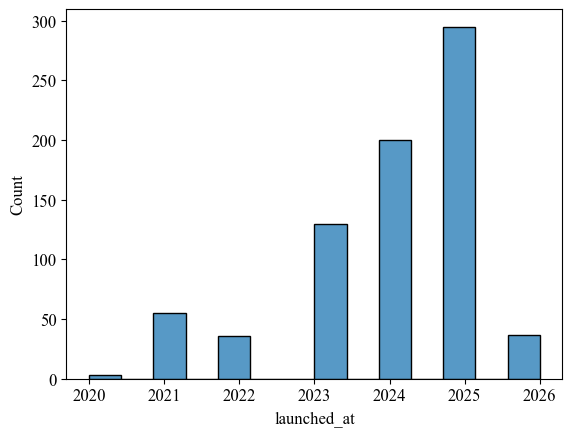

In [33]:
sns.histplot(work['launched_at'].dt.year)

Большая часть наблюдений сконцентрирована во временной период 2023-2026, это совпадает со временем популяризации ИИ и запуском первой публичной модели ChatGPT